## Install

In [ ]:

%pip install -q rtmlib onnxruntime-gpu opencv-python

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [97]:
%pip install -q rembg[gpu]

In [96]:
!nvidia-smi

Sun Nov 22 13:27:33 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   54C    P8             13W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Download Data

In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [85]:
!ls '/content/drive/MyDrive/Colab Notebooks/img/'
!mkdir data
!cp '/content/drive/MyDrive/Colab Notebooks/img/000003.png' './data/000003.png'
!cp '/content/drive/MyDrive/Colab Notebooks/img/000004.png' './data/000004.png'
!cp '/content/drive/MyDrive/Colab Notebooks/img/000004-resize.png' './data/000004-resize.png'


000003.png  000004.png	000004-resize.png
mkdir: cannot create directory ‘data’: File exists


In [105]:
# 画像読み込み（基準にしたい構図と、合わせたい画像）
import cv2


ref_img = cv2.imread('./data/000004.png')
tgt_img = cv2.imread('./data/000003.png')

### alignedの結果をダウンロード

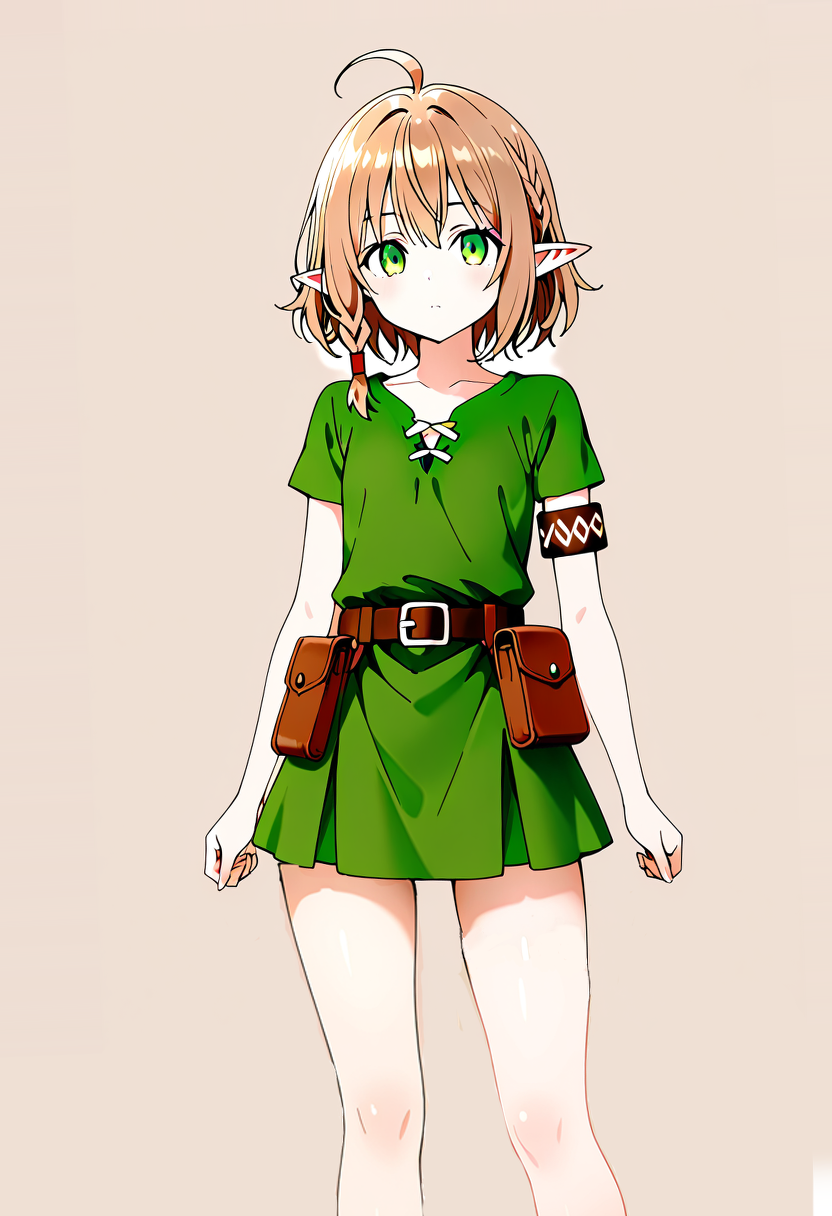

In [90]:
from IPython.display import Image, display

# パスを指定して表示（widthで表示サイズも調整可能）
display(Image('aligned_target.png', width=400))

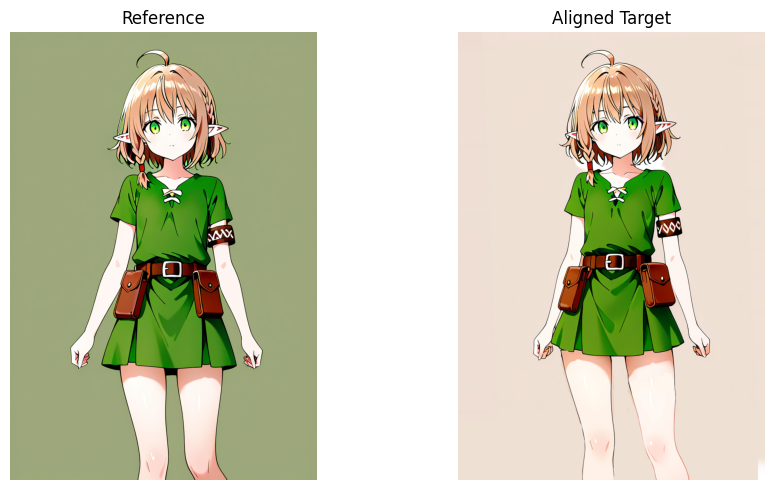

In [89]:
import cv2
import matplotlib.pyplot as plt

# 例：基準画像と位置合わせ後の画像を横に並べて比較
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

axes[0].imshow(cv2.cvtColor(ref_img, cv2.COLOR_BGR2RGB))
axes[0].set_title('Reference')
axes[0].axis('off')  # 目盛りを消す

axes[1].imshow(cv2.cvtColor(aligned_img, cv2.COLOR_BGR2RGB))
axes[1].set_title('Aligned Target')
axes[1].axis('off')

plt.tight_layout()
plt.show()

## Whole Body計算

In [106]:
from rtmlib import Wholebody

# モデルの読み込み（初回のみ自動でONNXモデルがDLされます）
# GPUランタイムなら device='cuda'、CPUなら 'cpu'
wholebody = Wholebody(
    to_openpose=False,  # COCO WholeBody形式（133点）を使用
    mode='performance', # 高精度なRTMW系モデルを使用
    backend='onnxruntime',
    device='cuda'
)


# キーポイント検出
ref_kpts, ref_scores = wholebody(ref_img)
tgt_kpts, tgt_scores = wholebody(tgt_img)

# 1人目のキャラクターの座標を取得
ref_p = ref_kpts[0]
tgt_p = tgt_kpts[0]



load /root/.cache/rtmlib/hub/checkpoints/yolox_m_8xb8-300e_humanart-c2c7a14a.onnx with onnxruntime backend
load /root/.cache/rtmlib/hub/checkpoints/rtmw-dw-x-l_simcc-cocktail14_270e-384x288_20231122.onnx with onnxruntime backend


## 基準画像（ref）に合わせて対象画像（target）の構図を揃える スケーリングも含む

import...
starting...


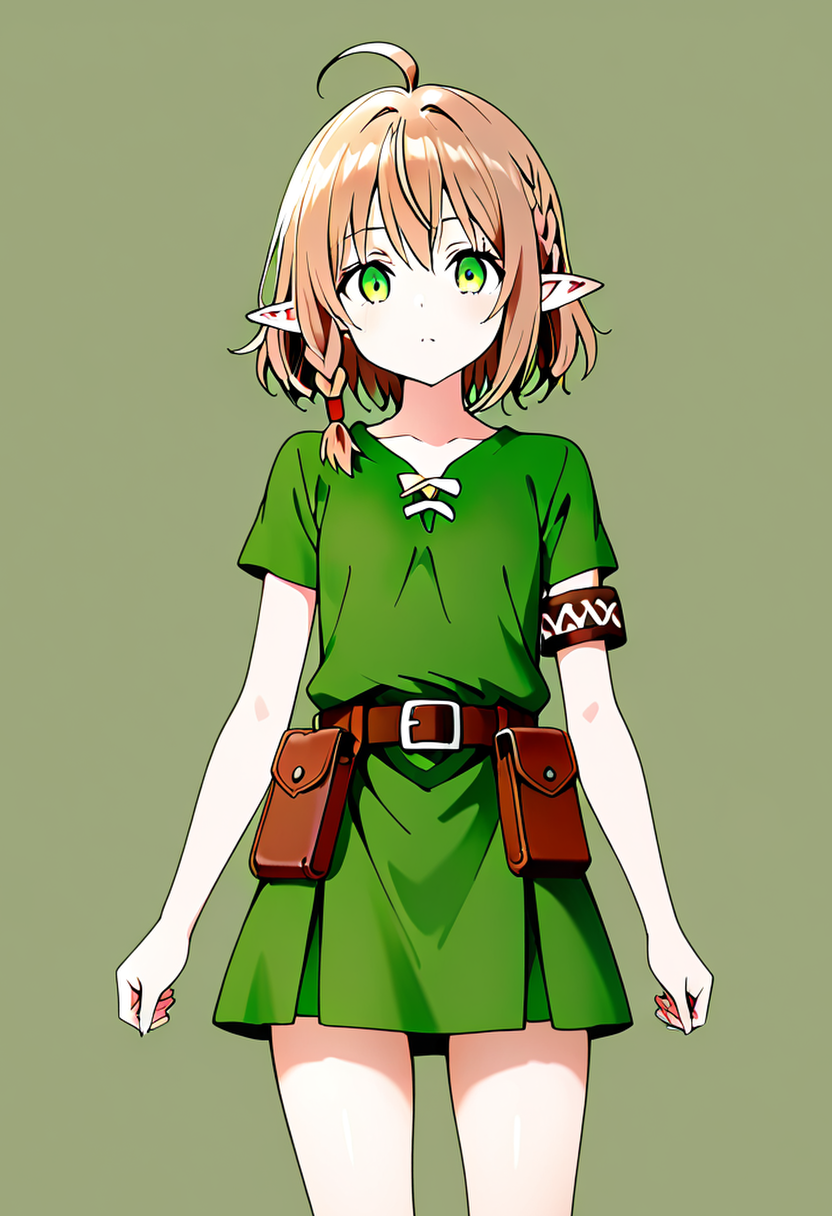

In [107]:
print("import...", flush=True)

import cv2
import numpy as np
from rtmlib import Wholebody, draw_skeleton
from IPython.display import Image, display

print("starting...", flush=True)

# 位置合わせに使うキーポイントのインデックス（COCO形式）
# 0:鼻, 1:左目, 2:右目, 5:左肩, 6:右肩, 11:左腰, 12:右腰
# バストアップなら [1, 2, 5, 6]、全身・膝上なら [5, 6, 11, 12] が安定します
use_indices = [1, 2, 5, 6]

src_pts = np.array([tgt_p[i] for i in use_indices], dtype=np.float32)
dst_pts = np.array([ref_p[i] for i in use_indices], dtype=np.float32)

# 相似変換行列を計算（歪みなし：移動・回転・スケールのみ）
M, _ = cv2.estimateAffinePartial2D(src_pts, dst_pts)

# 基準画像と同じ解像度に変換
# borderMode=cv2.BORDER_REPLICATE で無地背景の端を自然に引き伸ばす
h, w = ref_img.shape[:2]
aligned_img = cv2.warpAffine(
    tgt_img, M, (w, h),
    flags=cv2.INTER_LANCZOS4,
    borderMode=cv2.BORDER_REPLICATE
)

cv2.imwrite('aligned_target.png', aligned_img)

# デバッグ用：骨格がちゃんと取れているか確認する画像も出力
cv2.imwrite('debug_ref.png', draw_skeleton(ref_img.copy(), ref_kpts, ref_scores, kpt_thr=0.5))
cv2.imwrite('debug_tgt.png', draw_skeleton(tgt_img.copy(), tgt_kpts, tgt_scores, kpt_thr=0.5))


# パスを指定して表示（widthで表示サイズも調整可能）
display(Image('aligned_target.png', width=400))

### warp boundary check

✅ OK: 欠損なし（0.00%）


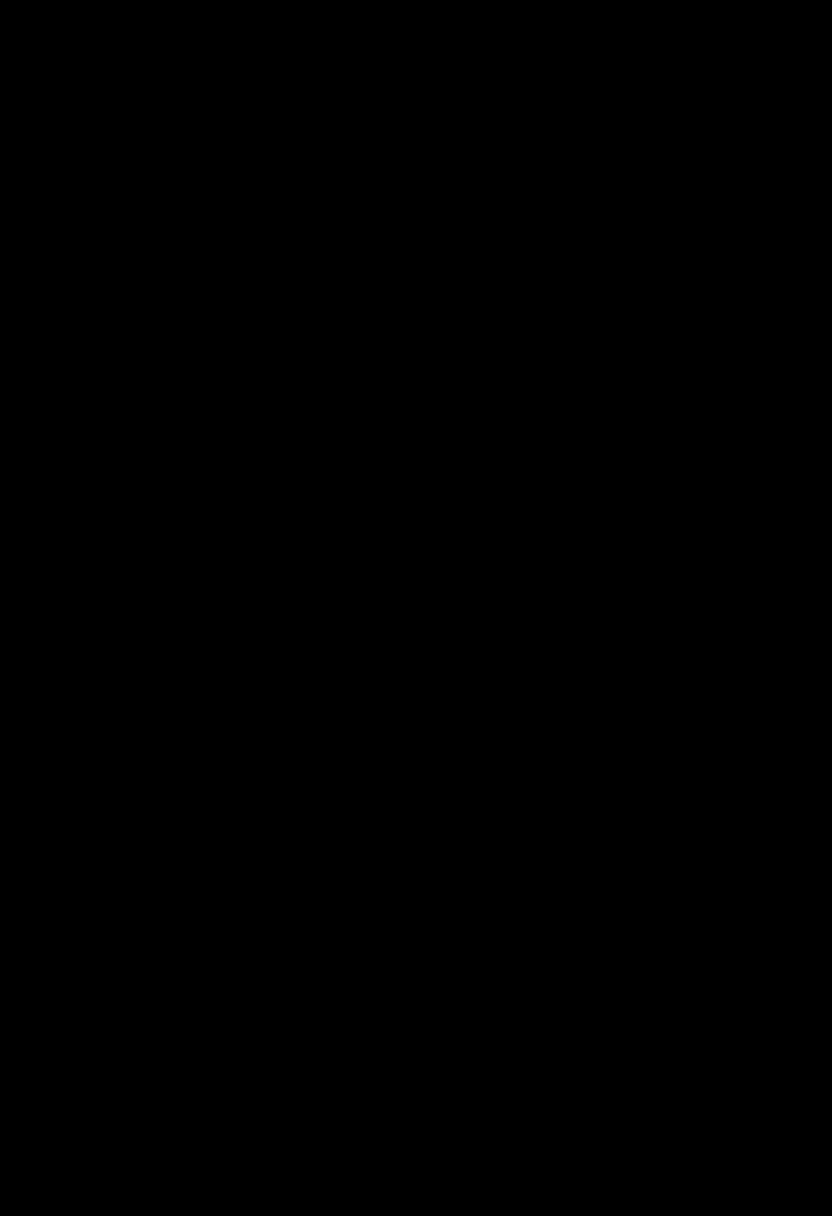

In [108]:
import cv2
import numpy as np
from IPython.display import Image, display
def warp_with_check(tgt_img, M, out_size, warn_threshold_pct=0.5):
    """
    warpAffineを実行し、元画像でカバーできない領域（欠損・引き伸ばし）があれば警告を出す。
    out_size: (w, h)
    """
    w, h = out_size

    # 1. 本体の変換
    aligned_img = cv2.warpAffine(
        tgt_img, M, (w, h),
        flags=cv2.INTER_LANCZOS4,
        borderMode=cv2.BORDER_REPLICATE
    )

    # 2. 元画像と同じサイズの白マスクを同じ行列で変換（外側は0=黒で埋める）
    valid_mask = np.full(tgt_img.shape[:2], 255, dtype=np.uint8)
    warped_valid = cv2.warpAffine(
        valid_mask, M, (w, h),
        flags=cv2.INTER_NEAREST,
        borderMode=cv2.BORDER_CONSTANT,
        borderValue=0
    )

    # 欠損領域（0の部分）を抽出（Inpaint用マスクとして白=255に反転）
    missing_mask = (warped_valid == 0).astype(np.uint8) * 255
    missing_pixels = np.count_nonzero(missing_mask)
    missing_pct = (missing_pixels / (w * h)) * 100

    # 3. 欠損がしきい値を超えていたら警告を出す
    if missing_pct >= warn_threshold_pct:
        # 上下左右のどの辺に欠損が出ているかチェック
        edges = []
        if np.any(missing_mask[0, :] > 0):  edges.append("上端")
        if np.any(missing_mask[-1, :] > 0): edges.append("下端")
        if np.any(missing_mask[:, 0] > 0):  edges.append("左端")
        if np.any(missing_mask[:, -1] > 0): edges.append("右端")

        print(f"⚠️ 警告: 元画像で補完できない領域が {missing_pct:.2f}% 発生しています（箇所: {', '.join(edges)}）")
    else:
        print(f"✅ OK: 欠損なし（{missing_pct:.2f}%）")

    return aligned_img, missing_mask

# --- 使い方 ---
h, w = ref_img.shape[:2]
aligned_img, missing_mask = warp_with_check(tgt_img, M, (w, h))

# 欠損があった場合、そのままInpaint用マスクとして保存可能
cv2.imwrite('inpaint_mask.png', missing_mask)
# パスを指定して表示（widthで表示サイズも調整可能）
display(Image('inpaint_mask.png', width=400))


## target画像とはスケーリング不変の変換

In [81]:
import numpy as np
import cv2

def estimate_rigid_transform(src_pts, dst_pts):
    """
    拡大縮小なし（スケール=1.0固定）で、
    位置（平行移動）と回転だけを最適に合わせる2x3変換行列を計算する
    """
    # 1. 各点群の重心（中心座標）を求める
    src_mean = np.mean(src_pts, axis=0)
    dst_mean = np.mean(dst_pts, axis=0)

    # 2. 重心を原点に揃える
    src_centered = src_pts - src_mean
    dst_centered = dst_pts - dst_mean

    # 3. SVD（特異値分解）で最適な回転行列 R だけを求める
    H = src_centered.T @ dst_centered
    U, S, Vt = np.linalg.svd(H)
    R = Vt.T @ U.T

    # 鏡像反転（裏返し）が起きてしまった場合の補正
    if np.linalg.det(R) < 0:
        Vt[-1, :] *= -1
        R = Vt.T @ U.T

    # 4. 平行移動ベクトル t を計算
    t = dst_mean - R @ src_mean

    # 5. OpenCVのwarpAffineで使える 2x3 行列にまとめる
    M = np.hstack([R, t.reshape(2, 1)])
    return M.astype(np.float32)

# 位置合わせに使うキーポイントのインデックス（COCO形式）
# 0:鼻, 1:左目, 2:右目, 5:左肩, 6:右肩, 11:左腰, 12:右腰
# バストアップなら [1, 2, 5, 6]、全身・膝上なら [5, 6, 11, 12] が安定します
use_indices = [1, 2, 5, 6]

src_pts = np.array([tgt_p[i] for i in use_indices], dtype=np.float32)
dst_pts = np.array([ref_p[i] for i in use_indices], dtype=np.float32)
M = estimate_rigid_transform(src_pts, dst_pts)

h, w = ref_img.shape[:2]
aligned_img = cv2.warpAffine(
    tgt_img, M, (w, h),
    flags=cv2.INTER_LANCZOS4,
    borderMode=cv2.BORDER_REPLICATE
)

cv2.imwrite('aligned_target.png', aligned_img)

True

## 背景の統一化

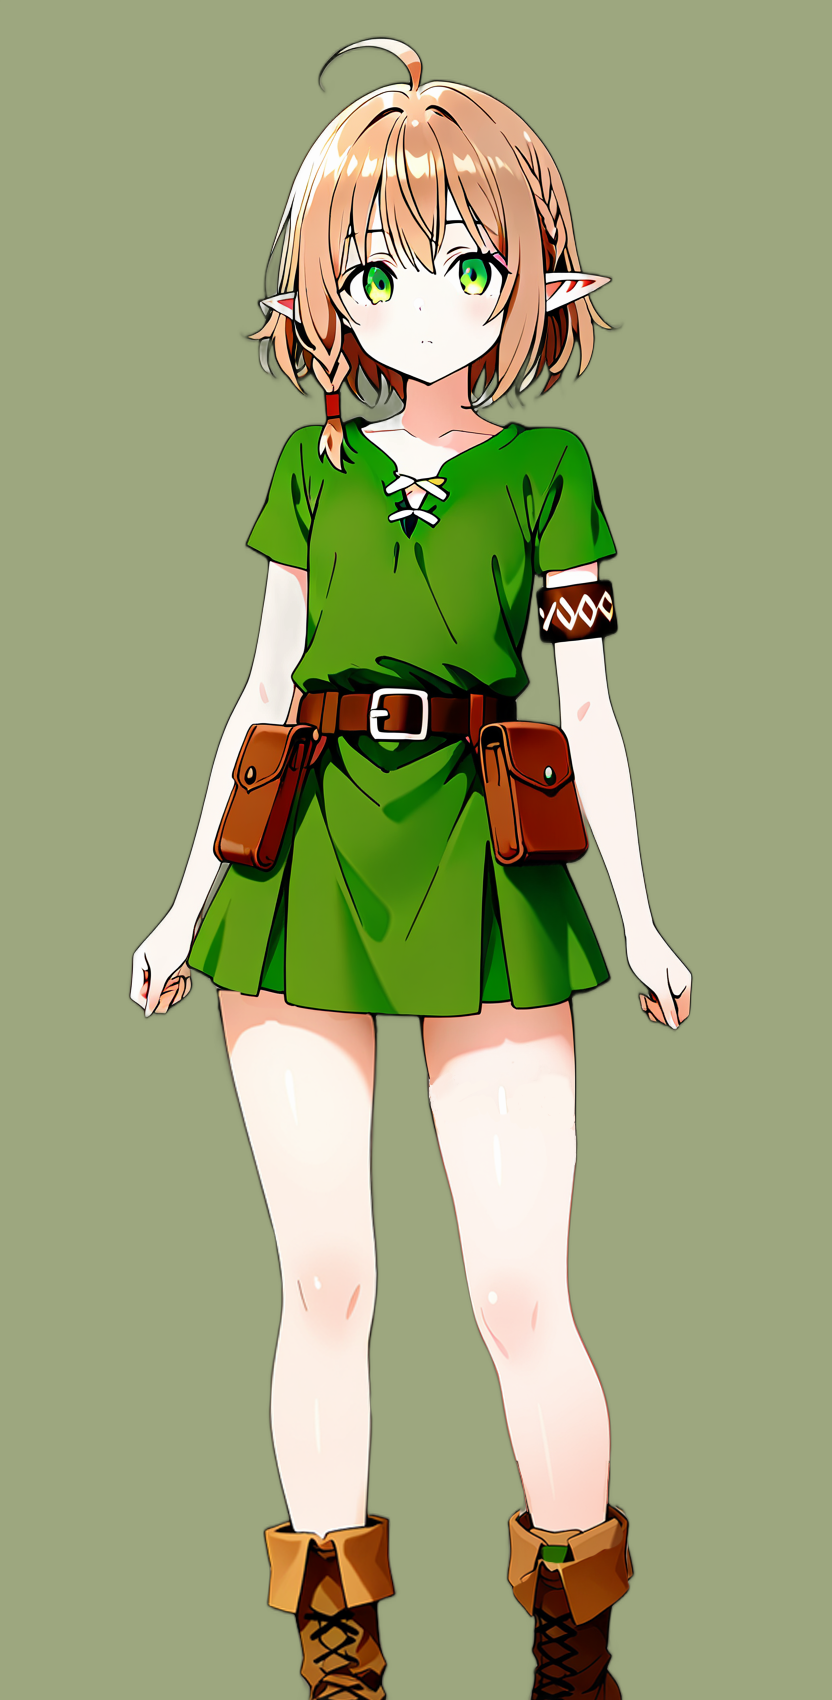

In [98]:
import cv2
import numpy as np
from rembg import remove, new_session
from IPython.display import Image, display


# アニメ特化モデルを一度だけ読み込んで使い回す（高速化）
anime_session = new_session("isnet-anime")

def get_bg_color(img):
    """画像の四隅のピクセルから背景色（BGRの中央値）を自動取得"""
    corners = np.array([
        img[0, 0], img[0, -1],
        img[-1, 0], img[-1, -1]
    ])
    return np.median(corners, axis=0).astype(np.uint8)

def unify_background(tgt_img, ref_img=None, bg_color_bgr=None):
    """
    tgt_imgの背景を切り抜き、ref_imgの背景色（または指定BGR色）で塗りつぶす
    """
    # 1. 背景色の決定
    if bg_color_bgr is None:
        bg_color_bgr = get_bg_color(ref_img) if ref_img is not None else np.array([255, 255, 255], dtype=np.uint8)
    else:
        bg_color_bgr = np.array(bg_color_bgr, dtype=np.uint8)

    # 2. アニメモデルで前景（キャラ）をRGBAで切り抜き
    tgt_rgb = cv2.cvtColor(tgt_img, cv2.COLOR_BGR2RGB)
    fg_rgba = remove(tgt_rgb, session=anime_session)

    # 3. アルファチャンネルを使って新しい背景色と綺麗に合成
    alpha = fg_rgba[:, :, 3:4].astype(np.float32) / 255.0
    fg_bgr = cv2.cvtColor(fg_rgba[:, :, :3], cv2.COLOR_RGB2BGR).astype(np.float32)
    bg_canvas = np.full_like(fg_bgr, bg_color_bgr, dtype=np.float32)

    result = (fg_bgr * alpha + bg_canvas * (1.0 - alpha)).astype(np.uint8)
    return result

# --- 使い方 ---
# 例1: 000003の背景色に000004を自動で合わせる
unified_img = unify_background(tgt_img, ref_img=ref_img)
cv2.imwrite('unified_target.png', unified_img)
# 例2: 指定した色（BGR形式）に統一する（例：薄いグレー）
# unified_img = unify_background(tgt_img, bg_color_bgr=(220, 220, 220))

# パスを指定して表示（widthで表示サイズも調整可能）
display(Image('unified_target.png', width=400))